# Petrobras 4T25 — análise exploratória com Python

**Autor:** Cassius Marcellus Brasil Rios Campos  
**Objetivo:** transformar tabelas de divulgação financeira em uma base organizada e comparar indicadores de resultado, caixa e endividamento.

**Fonte:** [Central de Resultados da Petrobras](https://www.investidorpetrobras.com.br/resultados-e-comunicados/central-de-resultados/), arquivo Excel em reais referente ao 4T25 fornecido para o projeto. O arquivo inclui também métricas em dólares e unidades não monetárias.

**Escopo:** Principais indicadores, DRE e DFC; trimestres 4T24, 3T25 e 4T25; anos 2024 e 2025. Os trimestres disponíveis não formam uma série contínua.

No Colab, execute as células na ordem e envie o arquivo Excel quando solicitado. Para executar localmente, abra este notebook na pasta do projeto e mantenha o arquivo em `dados/resultados_4t25.xlsx`.

Projeto desenvolvido com apoio de ChatGPT e Gemini na elaboração e revisão do código. O painel usa ipywidgets e requer execução em Colab ou Jupyter.


In [ ]:
import pandas as pd
import openpyxl

from pathlib import Path
from IPython.display import display

# Local: dados/resultados_4t25.xlsx. Colab: upload do Excel.
candidatos = [
    Path('dados/resultados_4t25.xlsx'),
    Path('/content/resultados_4t25.xlsx'),
    Path('/content/Resultados 4T25  - Tabela em Excel R$.xlsx')
]
file_path = next((p for p in candidatos if p.is_file()), None)

if file_path is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            'Coloque o Excel em dados/resultados_4t25.xlsx.'
        )
    enviados = files.upload()
    excel = [nome for nome in enviados if nome.lower().endswith('.xlsx')]
    if len(excel) != 1:
        raise ValueError('Envie exatamente um arquivo Excel do 4T25.')
    file_path = Path(excel[0])

# 1. Carregar o arquivo com openpyxl para listar todas as abas disponíveis
wb = openpyxl.load_workbook(file_path, read_only=True)
sheet_names = wb.sheetnames
print("=== ABAS DISPONÍVEIS NO ARQUIVO ===")
for name in sheet_names:
    print(f"- {name}")

# 2. Carregar a aba 'Principais indicadores' em seu formato bruto (sem pular linhas)
df_raw = pd.read_excel(file_path, sheet_name='Principais indicadores', header=None)

# 3. Visualizar as primeiras 15 linhas para diagnóstico visual
print("\n=== PREVIEW DAS PRIMEIRAS 15 LINHAS DA ABA 'Principais indicadores' ===")
display(df_raw.head(15))

=== ABAS DISPONÍVEIS NO ARQUIVO ===
- Principais indicadores
- Eventos exclusivos
- Investimentos
- Principais projetos
- Liquidez e recursos de capital
- Indicadores de endividamento
- Resultado E&P
- Resultado RTC
- Resultado G&EBC
- Reconciliação EBITDA ajustado
- DRE
- Balanço Patrimonial
- DFC
- Receita líquida
- CPV
- Despesas operacionais
- Resultado financeiro
- DRE por segmento
- ODO por segmento
- Ativo por segmento
- EBITDA Ajustado por segmento

=== PREVIEW DAS PRIMEIRAS 15 LINHAS DA ABA 'Principais indicadores' ===


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,Tabela 1 - Principais indicadores,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Variação (%),NaN,NaN
2,R$ milhões,4T25,3T25,NaN,4T24,NaN,2025.00,NaN,2024.00,NaN,4T25 X 3T25,NaN,4T25 X 4T24,2025 X 2024
3,Receita de vendas,127371,127906,NaN,121268,NaN,497549.00,NaN,490829.00,NaN,-0.4,NaN,5,1.4
4,Lucro bruto,58493,61117,NaN,58136,NaN,236998.00,NaN,246462.00,NaN,-4.3,NaN,0.6,-3.8
5,Despesas operacionais,-28833,-17666,NaN,-43081,NaN,-91128.00,NaN,-105794.00,NaN,63.2,NaN,-33.1,-13.9
6,Lucro líquido (Prejuízo) - Acionistas Petrobras,15563,32705,NaN,-17044,NaN,110129.00,NaN,36606.00,NaN,-52.4,NaN,−,200.8
7,Lucro líquido sem eventos exclusivos- Acionist...,25653,28509,NaN,17700,NaN,100937.00,NaN,102955.00,NaN,-10,NaN,44.9,-2
8,Fluxo de caixa operacional,54916,53655,NaN,47666,NaN,200333.00,NaN,204037.00,NaN,2.4,NaN,15.2,-1.8
9,Fluxo de caixa livre,19335,27015,NaN,21703,NaN,91635.00,NaN,124054.00,NaN,-28.4,NaN,-10.9,-26.1


In [ ]:
# 1. Remover colunas totalmente vazias que serviam apenas como separadores visuais
# Vamos identificar colunas que têm todos os valores nulos (NaN)
colunas_uteis = [col for col in df_raw.columns if not df_raw[col].isnull().all()]
df_filtered_cols = df_raw[colunas_uteis].copy()

# Este primeiro bloco cobre os indicadores até a alavancagem.
# Os quatro indicadores restantes serão tratados na célula de complemento.
df_dados_principais = df_filtered_cols.iloc[:15].copy()
notas_rodape = df_filtered_cols.iloc[19:].dropna(how='all').copy()

print('=== NOTAS EXPLICATIVAS ===')
for _, row in notas_rodape.iterrows():
    print(' '.join(str(v) for v in row if pd.notna(v)))

display(df_dados_principais)


=== NOTAS EXPLICATIVAS ===
(*) Vide reconciliação do Lucro líquido e EBITDA Ajustado sem eventos exclusivos.
(**) Índice calculado em dólares norte-americanos.


,0,1,2,4,6,8,10,11,12,13
0,Tabela 1 - Principais indicadores,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Variação (%),NaN,NaN
2,R$ milhões,4T25,3T25,4T24,2025.00,2024.00,4T25 X 3T25,NaN,4T25 X 4T24,2025 X 2024
3,Receita de vendas,127371,127906,121268,497549.00,490829.00,-0.4,NaN,5,1.4
4,Lucro bruto,58493,61117,58136,236998.00,246462.00,-4.3,NaN,0.6,-3.8
5,Despesas operacionais,-28833,-17666,-43081,-91128.00,-105794.00,63.2,NaN,-33.1,-13.9
6,Lucro líquido (Prejuízo) - Acionistas Petrobras,15563,32705,-17044,110129.00,36606.00,-52.4,NaN,−,200.8
7,Lucro líquido sem eventos exclusivos- Acionist...,25653,28509,17700,100937.00,102955.00,-10,NaN,44.9,-2
8,Fluxo de caixa operacional,54916,53655,47666,200333.00,204037.00,2.4,NaN,15.2,-1.8
9,Fluxo de caixa livre,19335,27015,21703,91635.00,124054.00,-28.4,NaN,-10.9,-26.1


In [ ]:
# 1. Definir novos cabeçalhos explícitos com base na análise visual da linha 2
# Coluna 0: 'indicador_original'
# Colunas de períodos: '4T25', '3T25', '4T24', '2025', '2024'
# Colunas de variação: 'var_4T25_3T25', 'var_filtro_vazio', 'var_4T25_4T24', 'var_2025_2024'

novas_colunas = [
    "indicador_original",
    "4T25", "3T25", "4T24",
    "2025", "2024",
    "var_4T25_3T25",
    "coluna_vazia_aux",  # Coluna de índice 11 que está vazia embaixo do título 'Variação (%)'
    "var_4T25_4T24",
    "var_2025_2024"
]

# Criar cópia dos dados principais a partir da linha 3 (onde começam os dados reais de indicadores)
df_padronizado = df_dados_principais.iloc[3:].copy()
df_padronizado.columns = novas_colunas

# Remover a coluna auxiliar vazia que restou sob a variação (%)
df_padronizado = df_padronizado.drop(columns=["coluna_vazia_aux"])

# 2. Padronizar os nomes dos indicadores mantendo a rastreabilidade
# Removemos espaços em branco nas pontas e as marcas de nota explicativa (* ou **)
import re
def limpar_nome_indicador(texto):
    if pd.isnull(texto):
        return ""
    texto_limpo = str(texto).strip()
    # Remove as marcas de notas como (*), (**), (x), etc.
    texto_limpo = re.sub(r'\s*\(\*+\)', '', texto_limpo)
    # Padroniza múltiplos espaços
    texto_limpo = re.sub(r'\s+', ' ', texto_limpo)
    return texto_limpo

df_padronizado['indicador_padrao'] = df_padronizado['indicador_original'].apply(limpar_nome_indicador)

# Reordenar para que o indicador padronizado apareça logo após o original
colunas_reordenadas = ['indicador_original', 'indicador_padrao'] + [col for col in df_padronizado.columns if col not in ['indicador_original', 'indicador_padrao']]
df_padronizado = df_padronizado[colunas_reordenadas]

print("=== TABELA COM CABEÇALHOS PADRONIZADOS (ETAPA 2) ===")
display(df_padronizado)

=== TABELA COM CABEÇALHOS PADRONIZADOS (ETAPA 2) ===


,indicador_original,indicador_padrao,4T25,3T25,4T24,2025,2024,var_4T25_3T25,var_4T25_4T24,var_2025_2024
3,Receita de vendas,Receita de vendas,127371,127906,121268,497549.00,490829.00,-0.4,5,1.4
4,Lucro bruto,Lucro bruto,58493,61117,58136,236998.00,246462.00,-4.3,0.6,-3.8
5,Despesas operacionais,Despesas operacionais,-28833,-17666,-43081,-91128.00,-105794.00,63.2,-33.1,-13.9
6,Lucro líquido (Prejuízo) - Acionistas Petrobras,Lucro líquido (Prejuízo) - Acionistas Petrobras,15563,32705,-17044,110129.00,36606.00,-52.4,−,200.8
7,Lucro líquido sem eventos exclusivos- Acionist...,Lucro líquido sem eventos exclusivos- Acionist...,25653,28509,17700,100937.00,102955.00,-10,44.9,-2
8,Fluxo de caixa operacional,Fluxo de caixa operacional,54916,53655,47666,200333.00,204037.00,2.4,15.2,-1.8
9,Fluxo de caixa livre,Fluxo de caixa livre,19335,27015,21703,91635.00,124054.00,-28.4,-10.9,-26.1
10,EBITDA ajustado,EBITDA ajustado,59923,63913,40968,237177.00,214419.00,-6.2,46.3,10.6
11,EBITDA ajustado sem eventos exclusivos (*),EBITDA ajustado sem eventos exclusivos,58989,65133,57508,244305.00,245786.00,-9.4,2.6,-0.6
12,Dívida bruta (US$ milhões),Dívida bruta (US$ milhões),69793,70711,60311,69793.00,60311.00,-1.3,15.7,15.7


In [ ]:
import numpy as np

# Criar uma cópia para o tratamento numérico
df_numerico = df_padronizado.copy()

# Colunas de períodos e variações que devem ser convertidas para numérico
colunas_valores = ['4T25', '3T25', '4T24', '2025', '2024', 'var_4T25_3T25', 'var_4T25_4T24', 'var_2025_2024']

def converter_para_numerico(valor):
    if pd.isnull(valor):
        return np.nan

    # Converter para string e limpar espaços
    val_str = str(valor).strip()

    # Substituir o travessão/meia-risca "−" e traços simples isolados por NaN
    if val_str in ['−', '−', '-', '']:
        return np.nan

    try:
        # Substituir separador de milhar e decimal se for texto do padrão brasileiro
        # Exemplo: '127.371' -> '127371'
        if ',' in val_str and '.' in val_str:
            val_str = val_str.replace('.', '').replace(',', '.')
        elif ',' in val_str:
            val_str = val_str.replace(',', '.')

        return float(val_str)
    except ValueError:
        return np.nan

# Aplicar a conversão em todas as colunas numéricas selecionadas
for col in colunas_valores:
    df_numerico[col] = df_numerico[col].apply(converter_para_numerico)

print("=== TABELA COM VALORES E VARIAÇÕES CONVERTIDOS PARA NUMÉRICO ===")
display(df_numerico)

=== TABELA COM VALORES E VARIAÇÕES CONVERTIDOS PARA NUMÉRICO ===


,indicador_original,indicador_padrao,4T25,3T25,4T24,2025,2024,var_4T25_3T25,var_4T25_4T24,var_2025_2024
3,Receita de vendas,Receita de vendas,127371.00,127906.00,121268.00,497549.00,490829.00,-0.4,5.0,1.4
4,Lucro bruto,Lucro bruto,58493.00,61117.00,58136.00,236998.00,246462.00,-4.3,0.6,-3.8
5,Despesas operacionais,Despesas operacionais,-28833.00,-17666.00,-43081.00,-91128.00,-105794.00,63.2,-33.1,-13.9
6,Lucro líquido (Prejuízo) - Acionistas Petrobras,Lucro líquido (Prejuízo) - Acionistas Petrobras,15563.00,32705.00,-17044.00,110129.00,36606.00,-52.4,NaN,200.8
7,Lucro líquido sem eventos exclusivos- Acionist...,Lucro líquido sem eventos exclusivos- Acionist...,25653.00,28509.00,17700.00,100937.00,102955.00,-10.0,44.9,-2.0
8,Fluxo de caixa operacional,Fluxo de caixa operacional,54916.00,53655.00,47666.00,200333.00,204037.00,2.4,15.2,-1.8
9,Fluxo de caixa livre,Fluxo de caixa livre,19335.00,27015.00,21703.00,91635.00,124054.00,-28.4,-10.9,-26.1
10,EBITDA ajustado,EBITDA ajustado,59923.00,63913.00,40968.00,237177.00,214419.00,-6.2,46.3,10.6
11,EBITDA ajustado sem eventos exclusivos (*),EBITDA ajustado sem eventos exclusivos,58989.00,65133.00,57508.00,244305.00,245786.00,-9.4,2.6,-0.6
12,Dívida bruta (US$ milhões),Dívida bruta (US$ milhões),69793.00,70711.00,60311.00,69793.00,60311.00,-1.3,15.7,15.7


In [ ]:
# 1. Isolar a tabela de variações (%) para uma tabela separada
cols_identificacao = ['indicador_original', 'indicador_padrao']
cols_variacoes = ['var_4T25_3T25', 'var_4T25_4T24', 'var_2025_2024']
df_variacoes_tidy = df_numerico[cols_identificacao + cols_variacoes].copy()

# 2. Criar a tabela de valores dos períodos (formato largo atual)
cols_periodos = ['4T25', '3T25', '4T24', '2025', '2024']
df_valores_largo = df_numerico[cols_identificacao + cols_periodos].copy()

# Função para mapear Moeda e Unidade com base no indicador
def extrair_metadados(row):
    indicador = row['indicador_original']
    if 'US$ milhões' in indicador:
        return 'USD', 'Milhões'
    elif '(x)' in indicador:
        return 'Multiplicador', 'Unidades'
    else:
        return 'BRL', 'Milhões'

# Aplicar mapeamento de metadados
df_valores_largo[['moeda', 'escala']] = df_valores_largo.apply(extrair_metadados, axis=1, result_type='expand')

# 3. Aplicar a transformação para formato longo (Melt)
df_valores_longo = pd.melt(
    df_valores_largo,
    id_vars=['indicador_original', 'indicador_padrao', 'moeda', 'escala'],
    value_vars=cols_periodos,
    var_name='periodo',
    value_name='valor'
)

# 4. Derivar o tipo de período (Trimestral se contiver 'T', senão Anual)
df_valores_longo['tipo_periodo'] = df_valores_longo['periodo'].apply(
    lambda p: 'Trimestral' if 'T' in str(p) else 'Anual'
)

# Adicionar a informação da aba de origem conforme a especificação do usuário
df_valores_longo['aba_origem'] = 'Principais indicadores'

# Reordenar as colunas para o formato final solicitado
colunas_finais = ['aba_origem', 'indicador_padrao', 'indicador_original', 'periodo', 'tipo_periodo', 'moeda', 'escala', 'valor']
df_valores_longo = df_valores_longo[colunas_finais]

print("=== TABELA DE VALORES EM FORMATO LONGO (TIDY DATA) ===")
display(df_valores_longo.head(15))

print("\n=== TABELA DE VARIAÇÕES SEPARADA ===")
display(df_variacoes_tidy)

=== TABELA DE VALORES EM FORMATO LONGO (TIDY DATA) ===

=== TABELA DE VARIAÇÕES SEPARADA ===


,aba_origem,indicador_padrao,indicador_original,periodo,tipo_periodo,moeda,escala,valor
0,Principais indicadores,Receita de vendas,Receita de vendas,4T25,Trimestral,BRL,Milhões,127371.00
1,Principais indicadores,Lucro bruto,Lucro bruto,4T25,Trimestral,BRL,Milhões,58493.00
2,Principais indicadores,Despesas operacionais,Despesas operacionais,4T25,Trimestral,BRL,Milhões,-28833.00
3,Principais indicadores,Lucro líquido (Prejuízo) - Acionistas Petrobras,Lucro líquido (Prejuízo) - Acionistas Petrobras,4T25,Trimestral,BRL,Milhões,15563.00
4,Principais indicadores,Lucro líquido sem eventos exclusivos- Acionist...,Lucro líquido sem eventos exclusivos- Acionist...,4T25,Trimestral,BRL,Milhões,25653.00
5,Principais indicadores,Fluxo de caixa operacional,Fluxo de caixa operacional,4T25,Trimestral,BRL,Milhões,54916.00
6,Principais indicadores,Fluxo de caixa livre,Fluxo de caixa livre,4T25,Trimestral,BRL,Milhões,19335.00
7,Principais indicadores,EBITDA ajustado,EBITDA ajustado,4T25,Trimestral,BRL,Milhões,59923.00
8,Principais indicadores,EBITDA ajustado sem eventos exclusivos,EBITDA ajustado sem eventos exclusivos (*),4T25,Trimestral,BRL,Milhões,58989.00
9,Principais indicadores,Dívida bruta (US$ milhões),Dívida bruta (US$ milhões),4T25,Trimestral,USD,Milhões,69793.00


,indicador_original,indicador_padrao,var_4T25_3T25,var_4T25_4T24,var_2025_2024
3,Receita de vendas,Receita de vendas,-0.4,5.0,1.4
4,Lucro bruto,Lucro bruto,-4.3,0.6,-3.8
5,Despesas operacionais,Despesas operacionais,63.2,-33.1,-13.9
6,Lucro líquido (Prejuízo) - Acionistas Petrobras,Lucro líquido (Prejuízo) - Acionistas Petrobras,-52.4,NaN,200.8
7,Lucro líquido sem eventos exclusivos- Acionist...,Lucro líquido sem eventos exclusivos- Acionist...,-10.0,44.9,-2.0
8,Fluxo de caixa operacional,Fluxo de caixa operacional,2.4,15.2,-1.8
9,Fluxo de caixa livre,Fluxo de caixa livre,-28.4,-10.9,-26.1
10,EBITDA ajustado,EBITDA ajustado,-6.2,46.3,10.6
11,EBITDA ajustado sem eventos exclusivos (*),EBITDA ajustado sem eventos exclusivos,-9.4,2.6,-0.6
12,Dívida bruta (US$ milhões),Dívida bruta (US$ milhões),-1.3,15.7,15.7


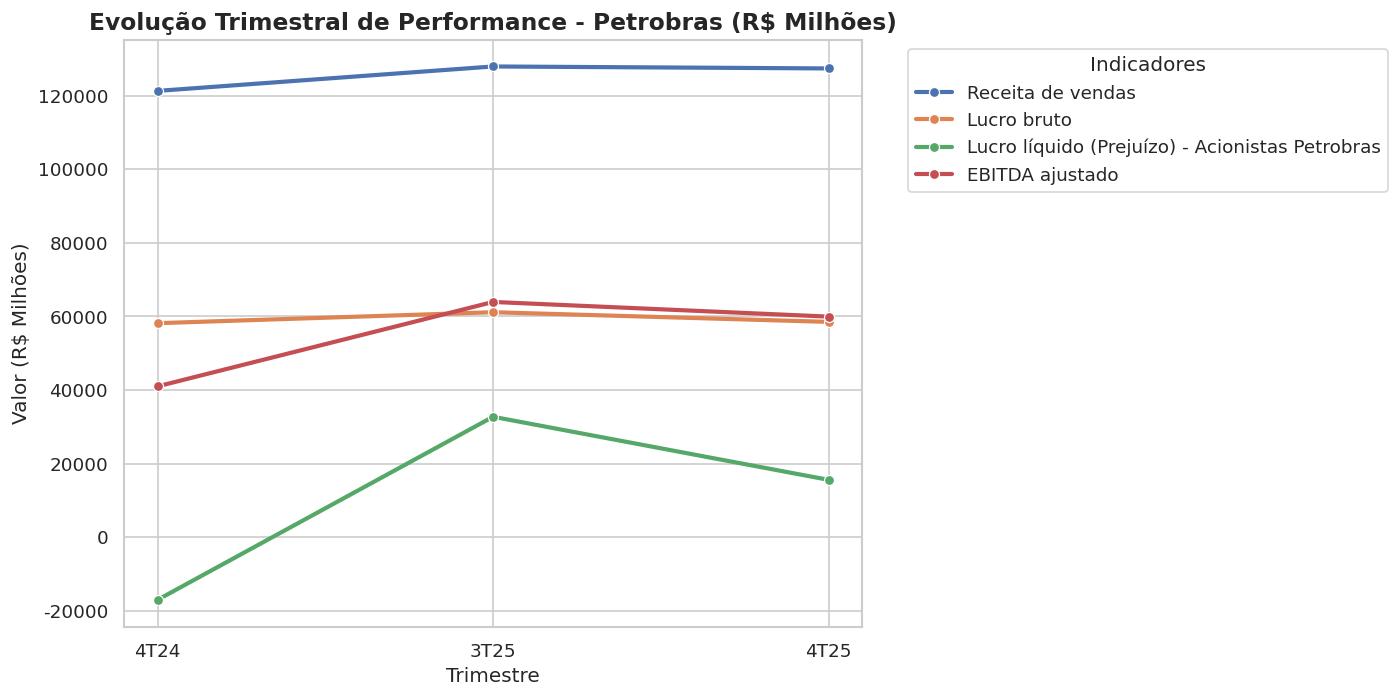

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o estilo visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['axes.unicode_minus'] = False  # Evita problemas com sinal de menos

# 1. Filtrar apenas dados trimestrais para análise de tendência de curto prazo
df_trimestral = df_valores_longo[df_valores_longo['tipo_periodo'] == 'Trimestral'].copy()

# Ordenar os períodos cronologicamente para o gráfico: 4T24 -> 3T25 -> 4T25
ordenacao_periodos = {'4T24': 0, '3T25': 1, '4T25': 2}
df_trimestral['ordem'] = df_trimestral['periodo'].map(ordenacao_periodos)
df_trimestral = df_trimestral.sort_values('ordem')

# 2. Visualização 1: Evolução dos Principais Indicadores de Performance (DRE e Caixa)
indicadores_performance = [
    'Receita de vendas',
    'Lucro bruto',
    'EBITDA ajustado',
    'Lucro líquido (Prejuízo) - Acionistas Petrobras'
]

df_perf = df_trimestral[df_trimestral['indicador_padrao'].isin(indicadores_performance)]

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_perf,
    x='periodo',
    y='valor',
    hue='indicador_padrao',
    marker='o',
    linewidth=2.5
)
plt.title('Evolução Trimestral de Performance - Petrobras (R$ Milhões)', fontsize=14, fontweight='bold')
plt.xlabel('Trimestre', fontsize=12)
plt.ylabel('Valor (R$ Milhões)', fontsize=12)
plt.legend(title='Indicadores', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

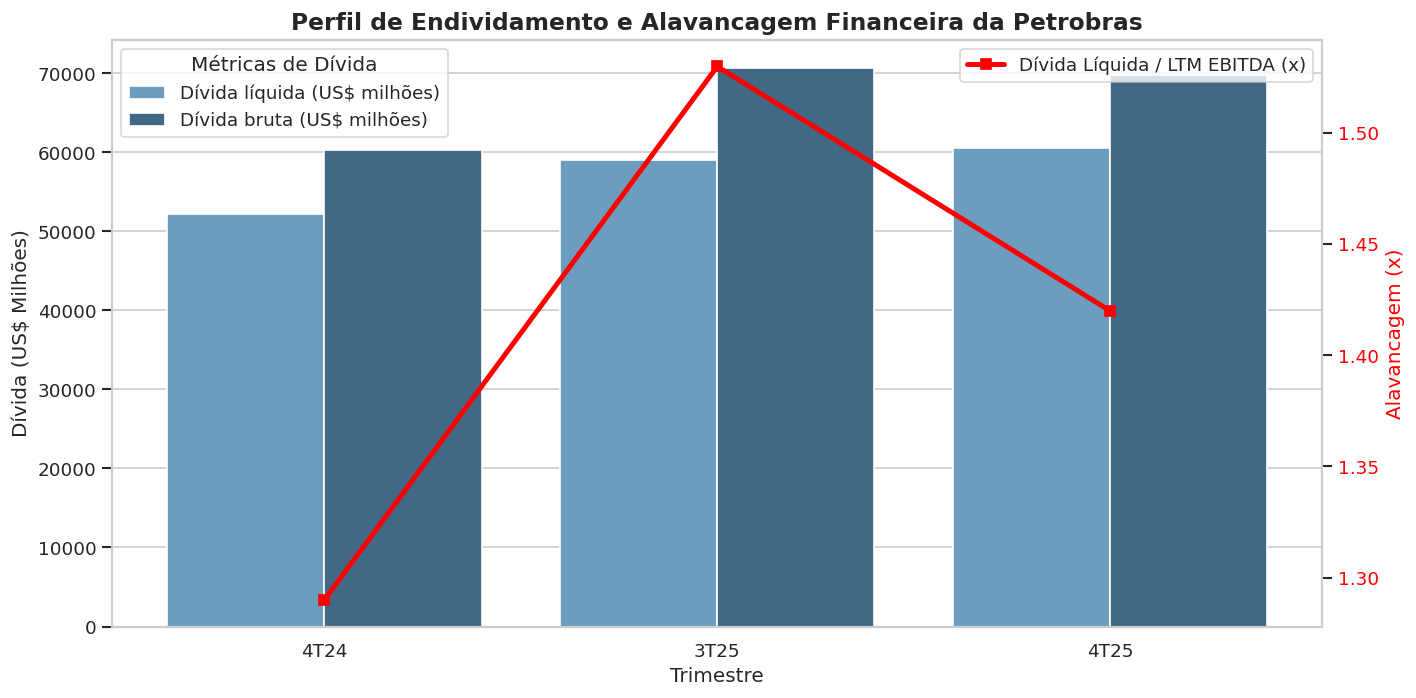

In [ ]:
# 3. Visualização 2: Comparativo da Alavancagem e Endividamento (Dívida em US$ Milhões)
indicadores_divida = ['Dívida bruta (US$ milhões)', 'Dívida líquida (US$ milhões)']
df_div = df_trimestral[df_trimestral['indicador_padrao'].isin(indicadores_divida)]

fig, ax1 = plt.subplots(figsize=(12, 6))

# Gráfico de barras para a Dívida Bruta e Líquida
sns.barplot(
    data=df_div,
    x='periodo',
    y='valor',
    hue='indicador_padrao',
    ax=ax1,
    palette='Blues_d'
)
ax1.set_title('Perfil de Endividamento e Alavancagem Financeira da Petrobras', fontsize=14, fontweight='bold')
ax1.set_ylabel('Dívida (US$ Milhões)', fontsize=12)
ax1.set_xlabel('Trimestre', fontsize=12)
ax1.legend(title='Métricas de Dívida', loc='upper left')

# Linha secundária para a relação Dívida Líquida / EBITDA Ajustado
ax2 = ax1.twinx()
df_alavancagem = df_trimestral[df_trimestral['indicador_padrao'] == 'Dívida líquida/LTM EBITDA Ajustado (x)']

serie_alavancagem = df_alavancagem.set_index('periodo')['valor'].reindex(
    ['4T24', '3T25', '4T25']
)
ax2.plot(
    range(len(serie_alavancagem)), serie_alavancagem.to_numpy(),
    color='red', marker='s', linewidth=3,
    label='Dívida Líquida / LTM EBITDA (x)'
)
ax2.set_ylabel('Alavancagem (x)', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')
ax2.legend(loc='upper right')
ax2.grid(False)

plt.tight_layout()
plt.show()

### Etapa 7: Carga e Diagnóstico das abas DRE e DFC
Antes de construir o dashboard interativo, precisamos compreender a estrutura exata das abas `DRE` e `DFC` do nosso arquivo Excel para aplicar a higienização adequada.

In [ ]:
import pandas as pd

# 1. Carregar as abas em formato bruto para analisar o cabeçalho e estrutura de linhas
df_dre_raw = pd.read_excel(file_path, sheet_name='DRE', header=None)
df_dfc_raw = pd.read_excel(file_path, sheet_name='DFC', header=None)

print("=== DIAGNÓSTICO BRUTO DA DRE (Primeiras 15 linhas) ===")
display(df_dre_raw.head(15))

print("\n=== DIAGNÓSTICO BRUTO DA DFC (Primeiras 15 linhas) ===")
display(df_dfc_raw.head(15))

=== DIAGNÓSTICO BRUTO DA DRE (Primeiras 15 linhas) ===

=== DIAGNÓSTICO BRUTO DA DFC (Primeiras 15 linhas) ===


,0,1,2,3,4,5
0,Tabela 11 - Demonstração do resultado – Consol...,NaN,NaN,NaN,NaN,NaN
1,R$ milhões,4T25,3T25,4T24,2025.0,2024.0
2,Receita de vendas,127371,127906,121268,497549.0,490829.0
3,Custo dos produtos e serviços vendidos,-68878,-66789,-63132,-260551.0,-244367.0
4,Lucro bruto,58493,61117,58136,236998.0,246462.0
5,Vendas,-7890,-7405,-6299,-28954.0,-26134.0
6,Gerais e administrativas,-2854,-2729,-2574,-10802.0,-9931.0
7,Custos exploratórios para extração de petróleo...,-2554,-1343,-1165,-6758.0,-4997.0
8,Custos com pesquisa e desenvolvimento tecnológico,-1272,-1268,-1281,-4814.0,-4281.0
9,Tributárias,-1986,-811,-630,-4241.0,-6708.0


,0,1,2,3,4,5
0,Tabela 13 - Demonstração do fluxo de caixa – C...,NaN,NaN,NaN,NaN,NaN
1,R$ milhões,4T25,3T25,4T24,2025,2024.0
2,Fluxo de caixa das atividades operacionais,NaN,NaN,NaN,NaN,NaN
3,Lucro líquido (prejuízo) do período,15653,32847,-16962,110605,37009.0
4,Ajustes para:,NaN,NaN,NaN,NaN,NaN
5,Resultado atuarial de planos de pensão e saúde,2435,2438,2274,9744,15788.0
6,Resultado de participações em investidas por e...,1175,-184,1886,242,3467.0
7,"Depreciação, depleção e amortização",22071,22389,17483,84388,67033.0
8,"Perda (reversão), líquida, no valor de recuper...",8540,-1539,9617,8347,9371.0
9,Ajuste a valor realizável líquido,-2,-16,-8,17,-214.0


### Etapa 8: Processamento e Padronização de DRE e DFC em Formato Tidy Data

In [ ]:
import numpy as np
import re

def processar_aba_demonstrativo(sheet_name, file_path):
    # Carrega a planilha bruta
    df_raw_sheet = pd.read_excel(file_path, sheet_name=sheet_name, header=None)

    # Encontra as colunas úteis (não totalmente vazias)
    colunas_uteis = [col for col in df_raw_sheet.columns if not df_raw_sheet[col].isnull().all()]
    df_filtered = df_raw_sheet[colunas_uteis].copy()

    # Identifica a linha do cabeçalho de períodos (contendo '4T25')
    idx_cabecalho = 1
    cabecalho_periodos = [str(x).strip() for x in df_filtered.iloc[idx_cabecalho].values]

    # Define novos nomes de colunas
    novas_colunas = []
    for i, col_name in enumerate(cabecalho_periodos):
        if i == 0:
            novas_colunas.append("indicador_original")
        else:
            novas_colunas.append(col_name)

    # Pula os cabeçalhos para obter as linhas de dados
    df_dados = df_filtered.iloc[idx_cabecalho + 1:].copy()
    df_dados.columns = novas_colunas

    # Remove linhas completamente nulas ou que sejam apenas subtítulos de seção vazios nos períodos
    df_dados = df_dados.dropna(subset=df_dados.columns[1:], how='all')
    df_dados = df_dados.dropna(subset=['indicador_original'])

    # Limpar nome do indicador
    def limpar_indicador(texto):
        if pd.isnull(texto): return ""
        t = str(texto).strip()
        t = re.sub(r'\s*\(\*+\)', '', t)
        t = re.sub(r'\s+', ' ', t)
        return t

    df_dados['indicador_padrao'] = df_dados['indicador_original'].apply(limpar_indicador)

    # Trata valores numéricos
    def converter_valor(valor):
        if pd.isnull(valor): return np.nan
        val_str = str(valor).strip()
        if val_str in ['−', '—', '-', '']: return np.nan
        try:
            if ',' in val_str and '.' in val_str:
                val_str = val_str.replace('.', '').replace(',', '.')
            elif ',' in val_str:
                val_str = val_str.replace(',', '.')
            return float(val_str)
        except ValueError:
            return np.nan

    colunas_valores = [c for c in novas_colunas if c != 'indicador_original']
    for col in colunas_valores:
        df_dados[col] = df_dados[col].apply(converter_valor)

    # Melt para formato longo
    df_long = pd.melt(
        df_dados,
        id_vars=['indicador_original', 'indicador_padrao'],
        value_vars=colunas_valores,
        var_name='periodo',
        value_name='valor'
    )

    df_long['tipo_periodo'] = df_long['periodo'].apply(lambda p: 'Trimestral' if 'T' in str(p) else 'Anual')
    df_long['moeda'] = 'BRL'
    df_long['escala'] = 'Milhões'
    df_long['aba_origem'] = sheet_name

    colunas_finais = ['aba_origem', 'indicador_padrao', 'indicador_original', 'periodo', 'tipo_periodo', 'moeda', 'escala', 'valor']
    return df_long[colunas_finais]

# Processar e unificar os dados da DRE e DFC
df_dre_tidy = processar_aba_demonstrativo('DRE', file_path)
df_dfc_tidy = processar_aba_demonstrativo('DFC', file_path)

# Unificar com a base anterior (Principais Indicadores) para ter um super dataset de análise
df_consolidado = pd.concat([df_valores_longo, df_dre_tidy, df_dfc_tidy], ignore_index=True)

# Padroniza anos que foram importados como "2025.0"
df_consolidado["periodo"] = (
    df_consolidado["periodo"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Confere se todos os períodos são os esperados
periodos_esperados = {"4T24", "3T25", "4T25", "2024", "2025"}

periodos_encontrados = set(df_consolidado["periodo"].unique())
periodos_inesperados = periodos_encontrados - periodos_esperados

assert not periodos_inesperados, (
    f"Períodos não reconhecidos: {periodos_inesperados}"
)

print("Períodos encontrados:")
print(sorted(periodos_encontrados))

print("=== DADOS UNIFICADOS COM SUCESSO ===")
print(f"Registros totais no dataset consolidado: {len(df_consolidado)}")
print(f"Abas mapeadas: {df_consolidado['aba_origem'].unique()}")
display(df_consolidado.sample(10))

Períodos encontrados:
['2024', '2025', '3T25', '4T24', '4T25']
=== DADOS UNIFICADOS COM SUCESSO ===
Registros totais no dataset consolidado: 410
Abas mapeadas: ['Principais indicadores' 'DRE' 'DFC']


,aba_origem,indicador_padrao,indicador_original,periodo,tipo_periodo,moeda,escala,valor
140,DRE,Tributos sobre o lucro,Tributos sobre o lucro,2025,Anual,BRL,Milhões,-39994.0
157,DRE,"Variações monetárias e cambiais, líquidas","Variações monetárias e cambiais, líquidas",2024,Anual,BRL,Milhões,-60866.0
371,DFC,Tributos sobre o lucro,Tributos sobre o lucro,2024,Anual,BRL,Milhões,17721.0
72,DRE,Despesas financeiras,Despesas financeiras,4T25,Trimestral,BRL,Milhões,-6195.0
227,DFC,Encerramento antecipado e alterações em pagame...,Encerramento antecipado e alterações em pagame...,3T25,Trimestral,BRL,Milhões,-787.0
215,DFC,Resultado atuarial de planos de pensão e saúde,Resultado atuarial de planos de pensão e saúde,3T25,Trimestral,BRL,Milhões,2438.0
217,DFC,"Depreciação, depleção e amortização","Depreciação, depleção e amortização",3T25,Trimestral,BRL,Milhões,22389.0
238,DFC,Outros benefícios a empregados,Outros benefícios a empregados,3T25,Trimestral,BRL,Milhões,2386.0
80,DRE,Acionistas não controladores,Acionistas não controladores,4T25,Trimestral,BRL,Milhões,90.0
364,DFC,"Depreciação, depleção e amortização","Depreciação, depleção e amortização",2024,Anual,BRL,Milhões,67033.0


### Etapa 9: Desenvolvimento do Dashboard Interativo no Google Colab

In [ ]:
# Recupera os quatro indicadores da planilha original.
# Posições conferidas especificamente neste arquivo do 4T25.
bruto = pd.read_excel(
    file_path,
    sheet_name="Principais indicadores",
    header=None
)

colunas_periodos = {
    "4T25": 1,
    "3T25": 2,
    "4T24": 4,
    "2025": 6,
    "2024": 8
}

# Linha, moeda, escala e unidade de cada indicador
metadados = [
    (15, "BRL/USD", "Unidades", "R$/US$"),
    (16, "USD", "Unidades", "US$/barril"),
    (17, "BRL", "Unidades", "R$/barril"),
    (18, None, "Fração", "Fração")
]

registros = []

for linha, moeda, escala, unidade in metadados:
    original = bruto.iloc[linha, 0]
    padrao = limpar_nome_indicador(original)

    for periodo, coluna in colunas_periodos.items():
        registros.append({
            "aba_origem": "Principais indicadores",
            "indicador_original": original,
            "indicador_padrao": padrao,
            "periodo": periodo,
            "tipo_periodo": (
                "Trimestral" if "T" in periodo else "Anual"
            ),
            "moeda": moeda,
            "escala": escala,
            "unidade": unidade,
            "valor": bruto.iloc[linha, coluna]
        })

df_complementares = pd.DataFrame(registros)

df_complementares["valor"] = pd.to_numeric(
    df_complementares["valor"],
    errors="raise"
)

# Explicita a unidade dos indicadores já tratados
df_consolidado["unidade"] = df_consolidado["moeda"].map({
    "BRL": "R$ milhões",
    "USD": "US$ milhões",
    "Multiplicador": "x"
})

# Evita duplicar os indicadores ao executar esta célula novamente
nomes = df_complementares["indicador_padrao"].unique()

substituir = (
    df_consolidado["aba_origem"].eq("Principais indicadores")
    & df_consolidado["indicador_padrao"].isin(nomes)
)

df_consolidado = pd.concat(
    [
        df_consolidado.loc[~substituir],
        df_complementares
    ],
    ignore_index=True
)

# Preserva as variações publicadas em seu formato original.
# No ROCE, elas são pontos percentuais, não variações em %.
df_variacoes_complementares = bruto.iloc[
    15:19, [0, 10, 12, 13]
].copy()

df_variacoes_complementares.columns = [
    "indicador_original",
    "var_4T25_3T25_original",
    "var_4T25_4T24_original",
    "var_2025_2024_original"
]

# Notas explicativas verdadeiras ficam separadas
notas_rodape = bruto.iloc[19:].dropna(how="all").copy()

print("Indicadores recuperados — 4T25:")
display(
    df_complementares.loc[
        df_complementares["periodo"] == "4T25",
        ["indicador_padrao", "valor", "unidade"]
    ]
)

print("Total de registros:", len(df_consolidado))

Indicadores recuperados — 4T25:
Total de registros: 430


,indicador_padrao,valor,unidade
0,Dólar médio de venda,5.390,R$/US$
5,Brent (US$/bbl),63.690,US$/barril
10,Preço derivados básicos - Mercado interno (R$/...,456.610,R$/barril
15,ROCE (Retorno sobre o Capital Empregado),0.066,Fração


In [ ]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, clear_output

assert "unidade" in df_consolidado.columns, (
    "Execute primeiro a célula que recupera os indicadores."
)

assert df_consolidado["unidade"].notna().all(), (
    "Existem indicadores sem unidade definida."
)

# Controles do painel
aba = widgets.Dropdown(
    options=sorted(df_consolidado["aba_origem"].unique()),
    value="DRE",
    description="Demonstrativo:",
    style={"description_width": "initial"}
)

tipo = widgets.Dropdown(
    options=sorted(df_consolidado["tipo_periodo"].unique()),
    value="Trimestral",
    description="Periodicidade:",
    style={"description_width": "initial"}
)

unidade = widgets.Dropdown(
    description="Unidade:",
    style={"description_width": "initial"}
)

indicadores = widgets.SelectMultiple(
    description="Indicadores:",
    rows=8,
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"}
)

saida = widgets.Output()

ordens = {
    "Trimestral": ["4T24", "3T25", "4T25"],
    "Anual": ["2024", "2025"]
}

# Evita redesenhar o painel durante a atualização dos controles
estado = {"atualizando": False}


def filtrar_base():
    return df_consolidado.loc[
        df_consolidado["aba_origem"].eq(aba.value)
        & df_consolidado["tipo_periodo"].eq(tipo.value)
    ].copy()


def desenhar(change=None):
    if estado["atualizando"]:
        return

    with saida:
        clear_output(wait=True)

        if not indicadores.value:
            print("Selecione pelo menos um indicador.")
            return

        dados = filtrar_base()

        dados = dados.loc[
            dados["unidade"].eq(unidade.value)
            & dados["indicador_padrao"].isin(indicadores.value)
        ]

        # Impede que duplicatas sejam agregadas silenciosamente
        chaves = ["indicador_padrao", "periodo"]

        if dados.duplicated(chaves).any():
            print("Há registros duplicados. Revise a base.")
            return

        tabela = dados.pivot(
            index="periodo",
            columns="indicador_padrao",
            values="valor"
        ).reindex(ordens[tipo.value])

        if tabela.empty or tabela.isna().all().all():
            print("Não há valores disponíveis para esta seleção.")
            return

        ax = tabela.plot(
            kind="bar",
            figsize=(11, 5),
            rot=0
        )

        rotulo = unidade.value

        if unidade.value == "Fração":
            ax.yaxis.set_major_formatter(
                PercentFormatter(xmax=1, decimals=1)
            )
            rotulo = "%"

        ax.set_title(
            f"Petrobras — {aba.value} ({tipo.value})"
        )
        ax.set_xlabel("Período")
        ax.set_ylabel(rotulo)
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.legend(
            title="Indicadores",
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

        plt.tight_layout()
        plt.show()

        print(f"Valores apresentados em: {rotulo}")

        formato = (
            "{:.1%}" if unidade.value == "Fração"
            else "{:,.2f}"
        )

        display(
            tabela.T.style.format(
                formato,
                na_rep="Não disponível"
            )
        )


def atualizar_controles(change=None):
    if estado["atualizando"]:
        return

    estado["atualizando"] = True

    try:
        dados = filtrar_base()

        # Ao mudar demonstrativo ou periodicidade, atualiza as unidades disponíveis
        mudou_unidade = (
            change is not None
            and change["owner"] is unidade
        )

        if not mudou_unidade:
            opcoes = sorted(
                dados["unidade"].dropna().unique()
            )

            anterior = unidade.value
            unidade.options = opcoes

            if anterior in opcoes:
                unidade.value = anterior
            else:
                unidade.value = opcoes[0] if opcoes else None

        disponiveis = sorted(
            dados.loc[
                dados["unidade"].eq(unidade.value),
                "indicador_padrao"
            ].unique()
        )

        indicadores.options = disponiveis
        indicadores.value = tuple(disponiveis[:2])

    finally:
        estado["atualizando"] = False

    desenhar()


aba.observe(atualizar_controles, names="value")
tipo.observe(atualizar_controles, names="value")
unidade.observe(atualizar_controles, names="value")
indicadores.observe(desenhar, names="value")

atualizar_controles()

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Petrobras — Painel de resultados</h3>"
        ),
        aba,
        tipo,
        unidade,
        indicadores,
        saida
    ])
)

### Etapa 10: Comparação entre lucro líquido e fluxo de caixa operacional
Comparação descritiva do lucro líquido consolidado e do caixa operacional, separando períodos trimestrais e anuais.



Comparação trimestral — R$ milhões

Comparação anual — R$ milhões


,lucro_liquido,caixa_operacional,diferenca_caixa_lucro
periodo,,,
4T24,-16962.0,47666.0,64628.0
3T25,32847.0,53655.0,20808.0
4T25,15653.0,54916.0,39263.0


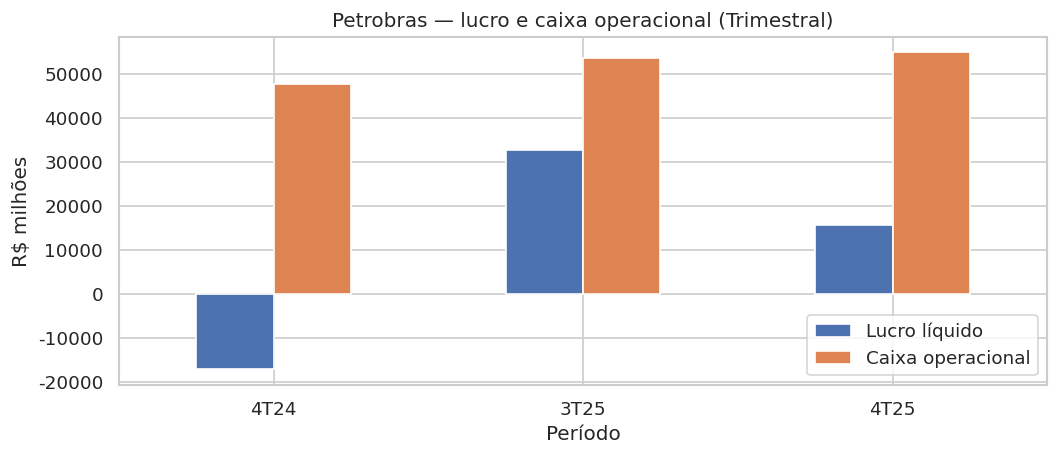

,lucro_liquido,caixa_operacional,diferenca_caixa_lucro
periodo,,,
2024,37009.0,204037.0,167028.0
2025,110605.0,200333.0,89728.0


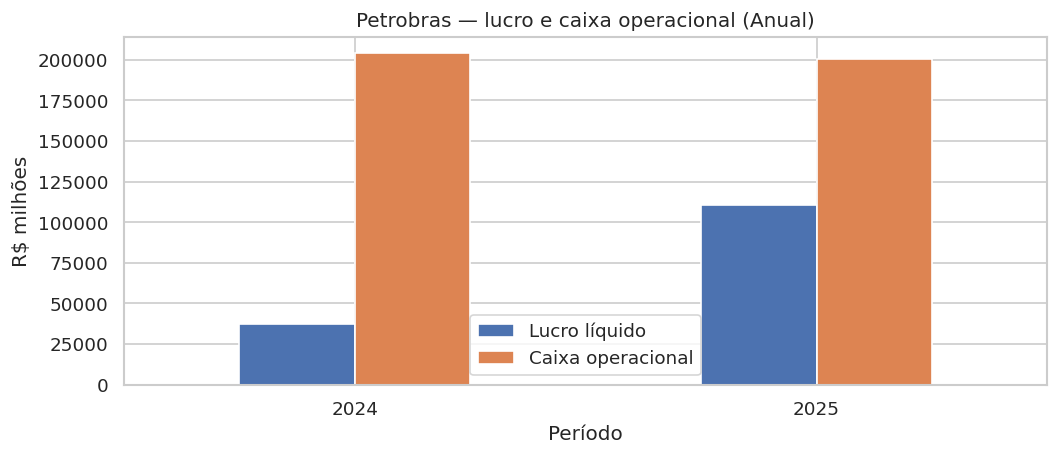

In [ ]:
import matplotlib.pyplot as plt

# Seleciona o lucro líquido consolidado da DRE
lucro = df_consolidado.loc[
    (df_consolidado["aba_origem"] == "DRE")
    & (
        df_consolidado["indicador_padrao"]
        == "Lucro (prejuízo) líquido do período"
    ),
    ["periodo", "tipo_periodo", "valor"]
].rename(columns={"valor": "lucro_liquido"})

# Seleciona o fluxo de caixa operacional da DFC
caixa = df_consolidado.loc[
    (df_consolidado["aba_origem"] == "DFC")
    & (
        df_consolidado["indicador_padrao"]
        == "Recursos líquidos gerados pelas atividades operacionais"
    ),
    ["periodo", "tipo_periodo", "valor"]
].rename(columns={"valor": "caixa_operacional"})

assert not lucro.empty, "Conta de lucro não encontrada."
assert not caixa.empty, "Conta de caixa não encontrada."

# Exige uma única observação por período em cada tabela
comparacao = lucro.merge(
    caixa,
    on=["periodo", "tipo_periodo"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert comparacao["_merge"].eq("both").all(), (
    "Existem períodos sem correspondência entre DRE e DFC."
)

comparacao = comparacao.drop(columns="_merge")

assert comparacao[
    ["lucro_liquido", "caixa_operacional"]
].notna().all().all(), "Há valores ausentes na comparação."

# Diferença descritiva; não representa uma conciliação contábil
comparacao["diferenca_caixa_lucro"] = (
    comparacao["caixa_operacional"]
    - comparacao["lucro_liquido"]
)

# Mostra cada periodicidade separadamente
grupos = {
    "Trimestral": ["4T24", "3T25", "4T25"],
    "Anual": ["2024", "2025"]
}

for tipo_periodo, ordem in grupos.items():
    tabela = (
        comparacao.loc[
            comparacao["tipo_periodo"] == tipo_periodo
        ]
        .set_index("periodo")
        .reindex(ordem)
    )

    print(
        f"\nComparação {tipo_periodo.lower()} — R$ milhões"
    )

    display(tabela[
        [
            "lucro_liquido",
            "caixa_operacional",
            "diferenca_caixa_lucro"
        ]
    ])

    tabela[
        ["lucro_liquido", "caixa_operacional"]
    ].plot(
        kind="bar",
        figsize=(9, 4),
        rot=0
    )

    plt.title(
        "Petrobras — lucro e caixa operacional "
        f"({tipo_periodo})"
    )
    plt.xlabel("Período")
    plt.ylabel("R$ milhões")
    plt.legend(["Lucro líquido", "Caixa operacional"])
    plt.tight_layout()
    plt.show()

### Metodologia e limitações

Este projeto apresenta uma análise exploratória dos resultados da Petrobras, utilizando as abas Principais indicadores, DRE e DFC da planilha de resultados do 4T25.

O tratamento inclui padronização dos indicadores e períodos, transformação para formato longo e identificação das moedas, escalas e unidades. A base final contém 430 registros.

Valores negativos foram preservados. Células vazias e traços isolados foram tratados como valores ausentes, sem substituição automática por zero. Os nomes originais dos indicadores foram mantidos para rastreabilidade.

O painel separa periodicidades e unidades. O ROCE permanece armazenado como fração e é apresentado como percentual. Suas variações publicadas em pontos percentuais foram preservadas separadamente.

A comparação entre lucro líquido e caixa operacional é descritiva. Não foi utilizada correlação entre períodos anuais e trimestrais sobrepostos. A diferença entre lucro e caixa não constitui uma conciliação contábil nem explica, por si só, suas causas.

O código utiliza posições de linhas e colunas específicas deste arquivo e pode precisar de adaptação para outras publicações.

Projeto desenvolvido com apoio de ChatGPT e Gemini na elaboração e revisão do código.


## Principais observações

- No 4T25, o lucro líquido consolidado foi R$ 15,653 bilhões e o caixa operacional foi R$ 54,916 bilhões. A diferença de R$ 39,263 bilhões é descritiva; sua explicação exige analisar os ajustes da DFC.
- Entre 2024 e 2025, o lucro líquido consolidado passou de R$ 37,009 bilhões para R$ 110,605 bilhões, enquanto o caixa operacional passou de R$ 204,037 bilhões para R$ 200,333 bilhões. A melhora do lucro não foi acompanhada de aumento do caixa operacional nesse comparativo.
- O ROCE foi 7,2% no 4T24, 5,7% no 3T25 e 6,6% no 4T25: recuperação de 0,9 ponto percentual frente ao 3T25 e redução de 0,6 ponto percentual frente ao 4T24.

Estas observações não atribuem causas às variações. Lucro consolidado inclui acionistas não controladores e difere do lucro atribuível aos acionistas Petrobras.
